In [ ]:
import pandas as pd
import numpy as np
import random
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
from sklearn.svm import SVC
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn import tree

df = pd.read_csv('credit_dataset.csv')
df


,Unnamed: 0,ID,GENDER,CAR,REALITY,NO_OF_CHILD,INCOME,INCOME_TYPE,EDUCATION_TYPE,FAMILY_TYPE,HOUSE_TYPE,FLAG_MOBIL,WORK_PHONE,PHONE,E_MAIL,FAMILY SIZE,BEGIN_MONTH,AGE,YEARS_EMPLOYED,TARGET
0,0,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,1.0,0.0,0.0,0.0,2.0,29.0,59.0,3.0,0.0
1,1,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,1.0,0.0,1.0,1.0,1.0,4.0,52.0,8.0,0.0
2,2,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,1.0,0.0,1.0,1.0,1.0,26.0,52.0,8.0,0.0
3,3,5008810,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,1.0,0.0,1.0,1.0,1.0,26.0,52.0,8.0,0.0
4,4,5008811,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,1.0,0.0,1.0,1.0,1.0,38.0,52.0,8.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17524,17524,5105533,F,N,Y,0,117000.0,State servant,Secondary / secondary special,Married,House / apartment,1.0,0.0,1.0,0.0,2.0,10.0,48.0,26.0,0.0
17525,17525,5105537,M,Y,N,0,202500.0,Working,Secondary / secondary special,Married,House / apartment,1.0,0.0,0.0,0.0,2.0,7.0,28.0,6.0,0.0
17526,17526,5105540,M,Y,N,0,202500.0,Working,Secondary / secondary special,Married,House / apartment,1.0,0.0,0.0,0.0,2.0,4.0,28.0,6.0,0.0
17527,17527,5105542,M,Y,N,0,202500.0,Working,Secondary / secondary special,Married,House / apartment,1.0,0.0,0.0,0.0,2.0,0.0,28.0,6.0,0.0


In [ ]:
# Function to introduce missing values in the dataset
def introduce_missing_values(df, missing_percentage):

    # Get the number of values to be replaced with NaN
    total_values = df.size
    n_missing = int(total_values * missing_percentage)

    # Randomly choose the positions to replace with NaN
    indices = [(row, col) for row in range(df.shape[0]) for col in range(df.shape[1])]
    random_indices = random.sample(indices, n_missing)

    # Replace the chosen positions with NaN
    for row, col in random_indices:
        df.iat[row, col] = np.nan

    return df

# Introduce 30% missing values
missing_percentage = 0.3
df_with_missing = introduce_missing_values(df, missing_percentage)

# Display the first few rows of the dataframe with missing values
print(df_with_missing.head())

# Save the modified dataset to a new CSV file
df_with_missing.to_csv('credit_dataset_with_missing_values.csv', index=False)

   Unnamed: 0         ID GENDER CAR REALITY  NO_OF_CHILD    INCOME  \
0         0.0        NaN    NaN   Y       Y          NaN  112500.0   
1         1.0  5008808.0      F   N       Y          NaN       NaN   
2         2.0        NaN    NaN   N       Y          0.0  270000.0   
3         3.0        NaN    NaN   N       Y          0.0  270000.0   
4         NaN        NaN      F   N       Y          0.0       NaN   

            INCOME_TYPE                 EDUCATION_TYPE           FAMILY_TYPE  \
0               Working                            NaN               Married   
1  Commercial associate  Secondary / secondary special  Single / not married   
2  Commercial associate  Secondary / secondary special                   NaN   
3  Commercial associate                            NaN                   NaN   
4                   NaN  Secondary / secondary special  Single / not married   

          HOUSE_TYPE  FLAG_MOBIL  WORK_PHONE  PHONE  E_MAIL  FAMILY SIZE  \
0  House / apartment  

In [ ]:
df_with_missing


,Unnamed: 0,ID,GENDER,CAR,REALITY,NO_OF_CHILD,INCOME,INCOME_TYPE,EDUCATION_TYPE,FAMILY_TYPE,HOUSE_TYPE,FLAG_MOBIL,WORK_PHONE,PHONE,E_MAIL,FAMILY SIZE,BEGIN_MONTH,AGE,YEARS_EMPLOYED,TARGET
0,0.0,NaN,NaN,Y,Y,NaN,112500.0,Working,NaN,Married,House / apartment,1.0,0.0,0.0,0.0,2.0,29.0,59.0,3.0,0.0
1,1.0,5008808.0,F,N,Y,NaN,NaN,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,1.0,0.0,NaN,1.0,1.0,4.0,NaN,8.0,0.0
2,2.0,NaN,NaN,N,Y,0.0,270000.0,Commercial associate,Secondary / secondary special,NaN,NaN,1.0,0.0,NaN,1.0,1.0,26.0,52.0,8.0,0.0
3,3.0,NaN,NaN,N,Y,0.0,270000.0,Commercial associate,NaN,NaN,NaN,1.0,NaN,1.0,1.0,NaN,26.0,NaN,NaN,NaN
4,NaN,NaN,F,N,Y,0.0,NaN,NaN,Secondary / secondary special,Single / not married,NaN,1.0,0.0,1.0,NaN,1.0,NaN,52.0,8.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17524,17524.0,5105533.0,NaN,N,Y,0.0,117000.0,NaN,Secondary / secondary special,NaN,House / apartment,1.0,0.0,1.0,0.0,2.0,NaN,NaN,26.0,0.0
17525,17525.0,5105537.0,NaN,NaN,NaN,0.0,202500.0,Working,Secondary / secondary special,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,28.0,6.0,0.0
17526,17526.0,5105540.0,M,NaN,NaN,0.0,NaN,NaN,Secondary / secondary special,Married,House / apartment,1.0,0.0,NaN,NaN,NaN,NaN,28.0,6.0,NaN
17527,17527.0,5105542.0,M,Y,N,0.0,NaN,Working,Secondary / secondary special,Married,NaN,NaN,0.0,NaN,0.0,2.0,0.0,NaN,6.0,NaN


Text(0.5, 1.0, 'Total Number of Null values for Each Column')

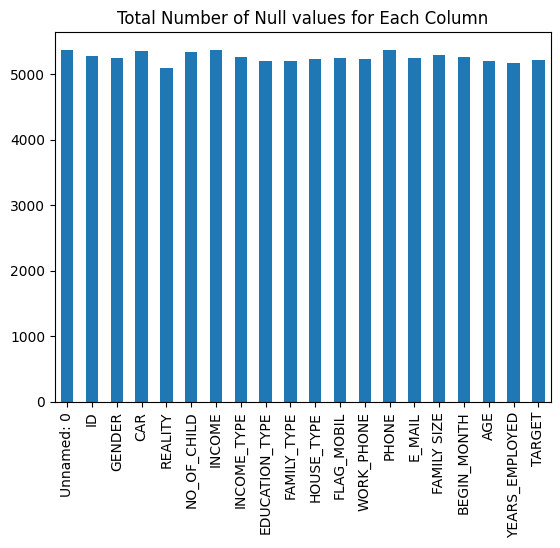

In [ ]:

df_with_missing.isnull().sum().plot(kind='bar')
plt.title("Total Number of Null values for Each Column")

In [ ]:
target_column_name = "TARGET"

In [ ]:
categorical_target_column = True
#categorical_target_column = False

In [ ]:
#Find out number of rows and columns
print(f'Total Number of Rows : {df_with_missing.shape[0]}')
print(f'Total Number of Columns : {df_with_missing.shape[1]}')

Total Number of Rows : 17529
Total Number of Columns : 20


In [ ]:
if categorical_target_column :
  print( df_with_missing[target_column_name].value_counts() )

TARGET
0.0    12229
1.0       80
Name: count, dtype: int64


In [ ]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.preprocessing import OneHotEncoder

df = pd.read_csv('credit_dataset_with_missing_values.csv')

# Identify categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns

# One-hot encode categorical columns
df_encoded = pd.get_dummies(df, columns=categorical_cols)

# Assume the target variable is in the last column
# Adjust this if the target variable is located elsewhere
X = df_encoded.iloc[:, :-1]
y = df_encoded.iloc[:, -1]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize the KNN classifier
knn = KNeighborsClassifier(n_neighbors=5)

# Fit the model on the training data
knn.fit(X_train, y_train)

# Predict on the test data
y_pred = knn.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

# Print the results
print(f'Accuracy: {accuracy:.2f}')
print('Classification Report:')
print(report)


Accuracy: 0.96
Classification Report:
              precision    recall  f1-score   support

       False       0.96      0.99      0.98      3371
        True       0.33      0.07      0.11       135

    accuracy                           0.96      3506
   macro avg       0.65      0.53      0.55      3506
weighted avg       0.94      0.96      0.95      3506



In [ ]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, accuracy_score
from sklearn.preprocessing import OneHotEncoder

# Load the dataset
df = pd.read_csv('credit_dataset_with_missing_values.csv')

# Identify categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns

# One-hot encode categorical columns
df_encoded = pd.get_dummies(df, columns=categorical_cols)

# Assume the target variable is in the last column
# Adjust this if the target variable is located elsewhere
X = df_encoded.iloc[:, :-1]
y = df_encoded.iloc[:, -1]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize the Naive Bayes classifier
nb = GaussianNB()

# Fit the model on the training data
nb.fit(X_train, y_train)

# Predict on the test data
y_pred = nb.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

# Print the results
print(f'Accuracy: {accuracy:.2f}')
print('Classification Report:')
print(report)


Accuracy: 0.96
Classification Report:
              precision    recall  f1-score   support

       False       0.96      1.00      0.98      3371
        True       0.00      0.00      0.00       135

    accuracy                           0.96      3506
   macro avg       0.48      0.50      0.49      3506
weighted avg       0.92      0.96      0.94      3506



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

df = pd.read_csv('credit_dataset_with_missing_values.csv')

# Identify categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns

# One-hot encode categorical columns
df_encoded = pd.get_dummies(df, columns=categorical_cols)

# Separate features and target
# Assume the target variable is in the last column
# Adjust this if the target variable is located elsewhere
X = df_encoded.iloc[:, :-1]
y = df_encoded.iloc[:, -1]

# Impute missing values using mean imputation
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X)

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_imputed, y, test_size=0.2, random_state=42)

# Initialize the Random Forest classifier
rf = RandomForestClassifier(n_estimators=100, random_state=42)

# Fit the model on the training data
rf.fit(X_train, y_train)

# Predict on the test data
y_pred = rf.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

# Print the results
print(f'Accuracy: {accuracy:.2f}')
print('Classification Report:')
print(report)

Accuracy: 0.96
Classification Report:
              precision    recall  f1-score   support

       False       0.96      1.00      0.98      3371
        True       1.00      0.03      0.06       135

    accuracy                           0.96      3506
   macro avg       0.98      0.51      0.52      3506
weighted avg       0.96      0.96      0.95      3506



In [ ]:
import pandas as pd
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
from sklearn.svm import SVC
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn import tree
df = pd.read_csv('credit_dataset_with_missing_values.csv')
df.head(5)

,Unnamed: 0,ID,GENDER,CAR,REALITY,NO_OF_CHILD,INCOME,INCOME_TYPE,EDUCATION_TYPE,FAMILY_TYPE,HOUSE_TYPE,FLAG_MOBIL,WORK_PHONE,PHONE,E_MAIL,FAMILY SIZE,BEGIN_MONTH,AGE,YEARS_EMPLOYED,TARGET
0,0.0,5008806.0,M,Y,Y,0.0,112500.0,Working,NaN,Married,NaN,1.0,NaN,NaN,NaN,2.0,NaN,59.0,3.0,NaN
1,1.0,5008808.0,F,N,NaN,NaN,NaN,Commercial associate,Secondary / secondary special,NaN,House / apartment,1.0,0.0,1.0,1.0,NaN,4.0,52.0,8.0,NaN
2,2.0,5008809.0,F,NaN,NaN,NaN,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,1.0,0.0,NaN,1.0,1.0,NaN,52.0,8.0,NaN
3,3.0,NaN,F,N,Y,NaN,270000.0,Commercial associate,NaN,Single / not married,House / apartment,NaN,0.0,1.0,1.0,1.0,NaN,52.0,8.0,0.0
4,4.0,5008811.0,F,NaN,Y,0.0,270000.0,NaN,Secondary / secondary special,Single / not married,NaN,1.0,NaN,1.0,1.0,1.0,38.0,NaN,8.0,NaN


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# Drop rows with any missing values
df_cleaned = df.dropna()
df_cleaned

,Unnamed: 0,ID,GENDER,CAR,REALITY,NO_OF_CHILD,INCOME,INCOME_TYPE,EDUCATION_TYPE,FAMILY_TYPE,HOUSE_TYPE,FLAG_MOBIL,WORK_PHONE,PHONE,E_MAIL,FAMILY SIZE,BEGIN_MONTH,AGE,YEARS_EMPLOYED,TARGET
148,148.0,5009000.0,M,Y,Y,0.0,157500.0,Working,Secondary / secondary special,Married,House / apartment,1.0,0.0,0.0,0.0,2.0,22.0,27.0,2.0,0.0
1600,1600.0,5021697.0,F,N,Y,1.0,180000.0,Commercial associate,Secondary / secondary special,Separated,House / apartment,1.0,0.0,1.0,1.0,2.0,41.0,51.0,6.0,0.0
2105,2105.0,5022644.0,M,Y,Y,1.0,135000.0,Commercial associate,Higher education,Married,House / apartment,1.0,0.0,0.0,0.0,3.0,53.0,32.0,0.0,0.0
2670,2670.0,5023657.0,F,N,N,0.0,225000.0,Commercial associate,Incomplete higher,Single / not married,House / apartment,1.0,0.0,0.0,0.0,1.0,9.0,28.0,3.0,0.0
3716,3716.0,5026507.0,F,Y,Y,2.0,112500.0,Working,Secondary / secondary special,Married,House / apartment,1.0,0.0,1.0,0.0,4.0,9.0,36.0,0.0,0.0
4947,4947.0,5033880.0,F,N,Y,0.0,202500.0,State servant,Higher education,Married,House / apartment,1.0,0.0,0.0,0.0,2.0,11.0,58.0,33.0,0.0
5116,5116.0,5035741.0,F,Y,Y,0.0,103500.0,State servant,Higher education,Separated,House / apartment,1.0,1.0,1.0,0.0,1.0,41.0,47.0,22.0,0.0
6513,6513.0,5041926.0,M,Y,N,0.0,157500.0,Working,Secondary / secondary special,Married,Rented apartment,1.0,1.0,1.0,0.0,2.0,38.0,34.0,1.0,0.0
8113,8113.0,5050607.0,M,N,N,0.0,157500.0,Working,Secondary / secondary special,Married,House / apartment,1.0,1.0,0.0,0.0,2.0,10.0,50.0,20.0,0.0
8954,8954.0,5053679.0,F,Y,Y,0.0,225000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,1.0,0.0,1.0,0.0,1.0,22.0,33.0,4.0,1.0


In [ ]:

# Identify categorical columns
categorical_cols = df_cleaned.select_dtypes(include=['object']).columns
categorical_cols

Index(['GENDER', 'CAR', 'REALITY', 'INCOME_TYPE', 'EDUCATION_TYPE',
       'FAMILY_TYPE', 'HOUSE_TYPE'],
      dtype='object')

In [ ]:
# One-hot encode categorical columns
df_encoded = pd.get_dummies(df_cleaned, columns=categorical_cols)
df_encoded

,Unnamed: 0,ID,NO_OF_CHILD,INCOME,FLAG_MOBIL,WORK_PHONE,PHONE,E_MAIL,FAMILY SIZE,BEGIN_MONTH,...,EDUCATION_TYPE_Secondary / secondary special,FAMILY_TYPE_Civil marriage,FAMILY_TYPE_Married,FAMILY_TYPE_Separated,FAMILY_TYPE_Single / not married,HOUSE_TYPE_Co-op apartment,HOUSE_TYPE_House / apartment,HOUSE_TYPE_Municipal apartment,HOUSE_TYPE_Office apartment,HOUSE_TYPE_Rented apartment
148,148.0,5009000.0,0.0,157500.0,1.0,0.0,0.0,0.0,2.0,22.0,...,True,False,True,False,False,False,True,False,False,False
1600,1600.0,5021697.0,1.0,180000.0,1.0,0.0,1.0,1.0,2.0,41.0,...,True,False,False,True,False,False,True,False,False,False
2105,2105.0,5022644.0,1.0,135000.0,1.0,0.0,0.0,0.0,3.0,53.0,...,False,False,True,False,False,False,True,False,False,False
2670,2670.0,5023657.0,0.0,225000.0,1.0,0.0,0.0,0.0,1.0,9.0,...,False,False,False,False,True,False,True,False,False,False
3716,3716.0,5026507.0,2.0,112500.0,1.0,0.0,1.0,0.0,4.0,9.0,...,True,False,True,False,False,False,True,False,False,False
4947,4947.0,5033880.0,0.0,202500.0,1.0,0.0,0.0,0.0,2.0,11.0,...,False,False,True,False,False,False,True,False,False,False
5116,5116.0,5035741.0,0.0,103500.0,1.0,1.0,1.0,0.0,1.0,41.0,...,False,False,False,True,False,False,True,False,False,False
6513,6513.0,5041926.0,0.0,157500.0,1.0,1.0,1.0,0.0,2.0,38.0,...,True,False,True,False,False,False,False,False,False,True
8113,8113.0,5050607.0,0.0,157500.0,1.0,1.0,0.0,0.0,2.0,10.0,...,True,False,True,False,False,False,True,False,False,False
8954,8954.0,5053679.0,0.0,225000.0,1.0,0.0,1.0,0.0,1.0,22.0,...,True,False,False,False,True,False,True,False,False,False


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25134 entries, 0 to 25133
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      17687 non-null  float64
 1   ID              17527 non-null  float64
 2   GENDER          17577 non-null  object 
 3   CAR             17632 non-null  object 
 4   REALITY         17522 non-null  object 
 5   NO_OF_CHILD     17501 non-null  float64
 6   INCOME          17466 non-null  float64
 7   INCOME_TYPE     17512 non-null  object 
 8   EDUCATION_TYPE  17529 non-null  object 
 9   FAMILY_TYPE     17753 non-null  object 
 10  HOUSE_TYPE      17685 non-null  object 
 11  FLAG_MOBIL      17547 non-null  float64
 12  WORK_PHONE      17725 non-null  float64
 13  PHONE           17552 non-null  float64
 14  E_MAIL          17672 non-null  float64
 15  FAMILY SIZE     17545 non-null  float64
 16  BEGIN_MONTH     17660 non-null  float64
 17  AGE             17632 non-null 

In [ ]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
Index: 26 entries, 148 to 25011
Data columns (total 34 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Unnamed: 0                                    26 non-null     float64
 1   ID                                            26 non-null     float64
 2   NO_OF_CHILD                                   26 non-null     float64
 3   INCOME                                        26 non-null     float64
 4   FLAG_MOBIL                                    26 non-null     float64
 5   WORK_PHONE                                    26 non-null     float64
 6   PHONE                                         26 non-null     float64
 7   E_MAIL                                        26 non-null     float64
 8   FAMILY SIZE                                   26 non-null     float64
 9   BEGIN_MONTH                                   26 non-null     float

In [ ]:
target_column_name = "TARGET"

In [ ]:
#Find out number of rows and columns
print(f'Total Number of Rows : {df_encoded.shape[0]}')
print(f'Total Number of Columns : {df_encoded.shape[1]}')

Total Number of Rows : 26
Total Number of Columns : 34


In [ ]:

  print( df_encoded[target_column_name].value_counts() )

TARGET
0.0    24
1.0     2
Name: count, dtype: int64


Text(0.5, 1.0, 'Total Number of Null values for Each Column')

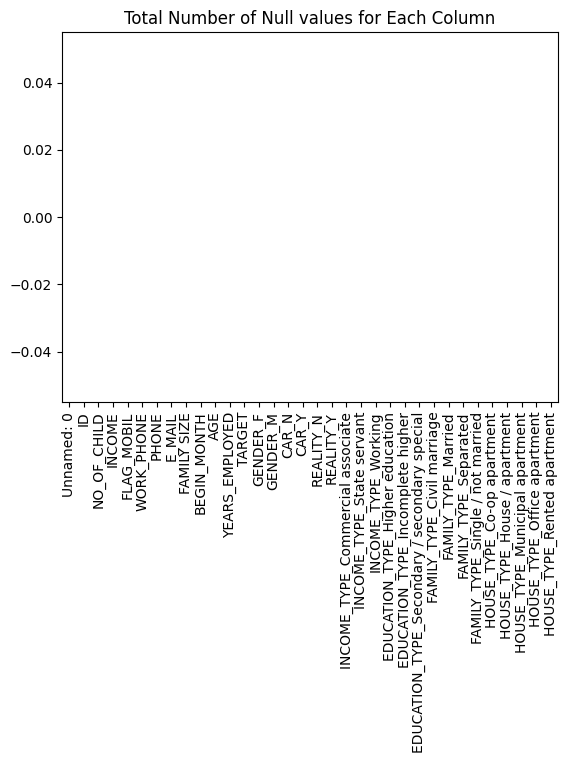

In [ ]:
df_encoded.isnull().sum().plot(kind='bar')
plt.title("Total Number of Null values for Each Column")


In [ ]:
X = df_encoded.drop(target_column_name , axis=1 )
y =  df_encoded[target_column_name]

enc = OrdinalEncoder()
X = enc.fit_transform( X )


le = LabelEncoder()
target_class = y.unique()
y = le.fit_transform( y )


In [ ]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.3, random_state=42)

In [ ]:

  clf = SVC()
  clf.fit( X_train , y_train )
  y_pred = clf.predict( X_test )

  print( classification_report( y_test , y_pred ) )



              precision    recall  f1-score   support

           0       0.88      1.00      0.93         7
           1       0.00      0.00      0.00         1

    accuracy                           0.88         8
   macro avg       0.44      0.50      0.47         8
weighted avg       0.77      0.88      0.82         8



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [ ]:

  clf = tree.DecisionTreeClassifier()
  clf.fit( X_train , y_train )
  y_pred = clf.predict( X_test )

  print( classification_report( y_test , y_pred ) )




              precision    recall  f1-score   support

           0       0.88      1.00      0.93         7
           1       0.00      0.00      0.00         1

    accuracy                           0.88         8
   macro avg       0.44      0.50      0.47         8
weighted avg       0.77      0.88      0.82         8



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [ ]:
# Import necessary libraries
import pandas as pd
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

df = pd.read_csv('credit_dataset_with_missing_values.csv')

# Identify categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns

# One-hot encode categorical columns
df_encoded = pd.get_dummies(df, columns=categorical_cols)

# Separate features and target
# Assume the target variable is in the last column
# Adjust this if the target variable is located elsewhere
X = df_encoded.iloc[:, :-1]
y = df_encoded.iloc[:, -1]

# Impute missing values using Iterative Imputer
imputer = IterativeImputer(random_state=42)
X_imputed = imputer.fit_transform(X)

# Convert the imputed array back to a DataFrame
df_imputed = pd.DataFrame(X_imputed, columns=X.columns)

# Add the target variable back to the imputed DataFrame
df_imputed['target'] = y.values

# Display the first few rows of the final dataset
print(df_imputed.head())

# Save the final dataset to a CSV file (optional)
# output_file_path = 'path_to_save_imputed_dataset/credit_dataset_imputed.csv'  # Update this with the desired path
# df_imputed.to_csv(output_file_path, index=False)


   Unnamed: 0            ID  NO_OF_CHILD         INCOME  FLAG_MOBIL  \
0         0.0  5.008806e+06     0.000000  112500.000000         1.0   
1         1.0  5.008808e+06     0.323684  199296.960903         1.0   
2         2.0  5.008809e+06    -0.049457  270000.000000         1.0   
3         3.0  5.008881e+06    -0.038883  270000.000000         1.0   
4         4.0  5.008811e+06     0.000000  270000.000000         1.0   

   WORK_PHONE    PHONE    E_MAIL  FAMILY SIZE  BEGIN_MONTH  ...  \
0    0.148594  0.24106  0.073959     2.000000    28.657136  ...   
1    0.000000  1.00000  1.000000     2.120556     4.000000  ...   
2    0.000000  0.33634  1.000000     1.000000    26.650452  ...   
3    0.000000  1.00000  1.000000     1.000000    26.717989  ...   
4    0.341977  1.00000  1.000000     1.000000    38.000000  ...   

   FAMILY_TYPE_Married  FAMILY_TYPE_Separated  \
0                  1.0                    0.0   
1                  0.0                    0.0   
2                  0.0 

In [ ]:
df_imputed

,Unnamed: 0,ID,NO_OF_CHILD,INCOME,FLAG_MOBIL,WORK_PHONE,PHONE,E_MAIL,FAMILY SIZE,BEGIN_MONTH,...,FAMILY_TYPE_Married,FAMILY_TYPE_Separated,FAMILY_TYPE_Single / not married,FAMILY_TYPE_Widow,HOUSE_TYPE_Co-op apartment,HOUSE_TYPE_House / apartment,HOUSE_TYPE_Municipal apartment,HOUSE_TYPE_Office apartment,HOUSE_TYPE_Rented apartment,target
0,0.0,5.008806e+06,0.000000,112500.000000,1.0,0.148594,0.24106,0.073959,2.000000,28.657136,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False
1,1.0,5.008808e+06,0.323684,199296.960903,1.0,0.000000,1.00000,1.000000,2.120556,4.000000,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,False
2,2.0,5.008809e+06,-0.049457,270000.000000,1.0,0.000000,0.33634,1.000000,1.000000,26.650452,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,False
3,3.0,5.008881e+06,-0.038883,270000.000000,1.0,0.000000,1.00000,1.000000,1.000000,26.717989,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,False
4,4.0,5.008811e+06,0.000000,270000.000000,1.0,0.341977,1.00000,1.000000,1.000000,38.000000,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25129,25129.0,5.149828e+06,0.325848,315000.000000,1.0,0.000000,0.00000,0.000000,2.000000,11.000000,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,False
25130,25130.0,5.148853e+06,0.040359,157500.000000,1.0,0.558059,1.00000,1.000000,2.000000,23.000000,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,False
25131,25131.0,5.149838e+06,0.000000,190119.389763,1.0,0.000000,1.00000,1.000000,2.000000,32.000000,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,False
25132,25132.0,5.148519e+06,0.000000,283500.000000,1.0,0.000000,0.00000,0.092472,2.000000,9.000000,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False


In [ ]:
target_column_name = "TARGET"

In [ ]:
df_imputed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25134 entries, 0 to 25133
Data columns (total 40 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Unnamed: 0                                    25134 non-null  float64
 1   ID                                            25134 non-null  float64
 2   NO_OF_CHILD                                   25134 non-null  float64
 3   INCOME                                        25134 non-null  float64
 4   FLAG_MOBIL                                    25134 non-null  float64
 5   WORK_PHONE                                    25134 non-null  float64
 6   PHONE                                         25134 non-null  float64
 7   E_MAIL                                        25134 non-null  float64
 8   FAMILY SIZE                                   25134 non-null  float64
 9   BEGIN_MONTH                                   25134 non-null 

In [ ]:

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_imputed, y, test_size=0.3, random_state=52)

# Initialize the Support Vector Machine classifier
svm = SVC(random_state=42)

# Fit the model on the training data
svm.fit(X_train, y_train)

# Predict on the test data
y_pred = svm.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

# Print the results
print(f'Accuracy: {accuracy:.2f}')
print('Classification Report:')
print(report)


Accuracy: 0.96
Classification Report:
              precision    recall  f1-score   support

       False       0.96      1.00      0.98      7228
        True       0.00      0.00      0.00       313

    accuracy                           0.96      7541
   macro avg       0.48      0.50      0.49      7541
weighted avg       0.92      0.96      0.94      7541



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [ ]:
import pandas as pd
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, accuracy_score


X_train, X_test, y_train, y_test = train_test_split(X_imputed, y, test_size=0.2, random_state=42)

# Initialize the Gradient Boosting classifier
gbc = GradientBoostingClassifier(random_state=42)

# Fit the model on the training data
gbc.fit(X_train, y_train)

# Predict on the test data
y_pred = gbc.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

# Print the results
print(f'Accuracy: {accuracy:.2f}')
print('Classification Report:')
print(report)

Accuracy: 0.96
Classification Report:
              precision    recall  f1-score   support

       False       0.96      1.00      0.98      4826
        True       0.38      0.01      0.03       201

    accuracy                           0.96      5027
   macro avg       0.67      0.51      0.50      5027
weighted avg       0.94      0.96      0.94      5027



In [ ]:
import pandas as pd
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score


X_train, X_test, y_train, y_test = train_test_split(X_imputed, y, test_size=0.2, random_state=42)

# Initialize the XGBoost classifier
xgb = XGBClassifier(random_state=42)

# Fit the model on the training data
xgb.fit(X_train, y_train)

# Predict on the test data
y_pred = xgb.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

# Print the results
print(f'Accuracy: {accuracy:.2f}')
print('Classification Report:')
print(report)

Accuracy: 0.96
Classification Report:
              precision    recall  f1-score   support

       False       0.97      0.99      0.98      4826
        True       0.54      0.22      0.31       201

    accuracy                           0.96      5027
   macro avg       0.76      0.61      0.65      5027
weighted avg       0.95      0.96      0.95      5027



In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score


In [ ]:
df = pd.read_csv('credit_dataset_with_missing_values.csv')
df.head(5)

,Unnamed: 0,ID,GENDER,CAR,REALITY,NO_OF_CHILD,INCOME,INCOME_TYPE,EDUCATION_TYPE,FAMILY_TYPE,HOUSE_TYPE,FLAG_MOBIL,WORK_PHONE,PHONE,E_MAIL,FAMILY SIZE,BEGIN_MONTH,AGE,YEARS_EMPLOYED,TARGET
0,0.0,5008806.0,M,Y,Y,0.0,112500.0,Working,NaN,Married,NaN,1.0,NaN,NaN,NaN,2.0,NaN,59.0,3.0,NaN
1,1.0,5008808.0,F,N,NaN,NaN,NaN,Commercial associate,Secondary / secondary special,NaN,House / apartment,1.0,0.0,1.0,1.0,NaN,4.0,52.0,8.0,NaN
2,2.0,5008809.0,F,NaN,NaN,NaN,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,1.0,0.0,NaN,1.0,1.0,NaN,52.0,8.0,NaN
3,3.0,NaN,F,N,Y,NaN,270000.0,Commercial associate,NaN,Single / not married,House / apartment,NaN,0.0,1.0,1.0,1.0,NaN,52.0,8.0,0.0
4,4.0,5008811.0,F,NaN,Y,0.0,270000.0,NaN,Secondary / secondary special,Single / not married,NaN,1.0,NaN,1.0,1.0,1.0,38.0,NaN,8.0,NaN


In [ ]:
# Identify categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns

# One-hot encode categorical columns
df_encoded = pd.get_dummies(df, columns=categorical_cols)

# Separate features and target
# Assume the target variable is in the last column
# Adjust this if the target variable is located elsewhere
X = df_encoded.iloc[:, :-1]
y = df_encoded.iloc[:, -1]

X

,Unnamed: 0,ID,NO_OF_CHILD,INCOME,FLAG_MOBIL,WORK_PHONE,PHONE,E_MAIL,FAMILY SIZE,BEGIN_MONTH,...,FAMILY_TYPE_Civil marriage,FAMILY_TYPE_Married,FAMILY_TYPE_Separated,FAMILY_TYPE_Single / not married,FAMILY_TYPE_Widow,HOUSE_TYPE_Co-op apartment,HOUSE_TYPE_House / apartment,HOUSE_TYPE_Municipal apartment,HOUSE_TYPE_Office apartment,HOUSE_TYPE_Rented apartment
0,0.0,5008806.0,0.0,112500.0,1.0,NaN,NaN,NaN,2.0,NaN,...,False,True,False,False,False,False,False,False,False,False
1,1.0,5008808.0,NaN,NaN,1.0,0.0,1.0,1.0,NaN,4.0,...,False,False,False,False,False,False,True,False,False,False
2,2.0,5008809.0,NaN,270000.0,1.0,0.0,NaN,1.0,1.0,NaN,...,False,False,False,True,False,False,True,False,False,False
3,3.0,NaN,NaN,270000.0,NaN,0.0,1.0,1.0,1.0,NaN,...,False,False,False,True,False,False,True,False,False,False
4,4.0,5008811.0,0.0,270000.0,1.0,NaN,1.0,1.0,1.0,38.0,...,False,False,False,True,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25129,25129.0,5149828.0,NaN,315000.0,1.0,0.0,0.0,0.0,2.0,11.0,...,False,False,False,False,False,False,True,False,False,False
25130,25130.0,NaN,NaN,157500.0,NaN,NaN,1.0,1.0,2.0,23.0,...,False,True,False,False,False,False,True,False,False,False
25131,25131.0,5149838.0,0.0,NaN,1.0,0.0,1.0,1.0,2.0,32.0,...,False,True,False,False,False,False,True,False,False,False
25132,25132.0,NaN,0.0,283500.0,1.0,0.0,0.0,NaN,2.0,9.0,...,False,True,False,False,False,False,False,False,False,False


In [ ]:
imputer = SimpleImputer(strategy='constant', fill_value=0)
X_imputed = imputer.fit_transform(X)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_imputed, y, test_size=0.2, random_state=42)


In [ ]:
classifier = DecisionTreeClassifier()


In [ ]:
classifier.fit(X_train, y_train)


DecisionTreeClassifier()

In [ ]:
predictions = classifier.predict(X_test)


In [ ]:
accuracy = accuracy_score(y_test, predictions)
print("Accuracy:", accuracy)


Accuracy: 0.9355480405808634


In [ ]:
# Import necessary libraries
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score

# Load the dataset
df = pd.read_csv('credit_dataset_with_missing_values.csv')

# Identify categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns

# One-hot encode categorical columns
df_encoded = pd.get_dummies(df, columns=categorical_cols)

# Separate features and target
# Assume the target variable is in the last column
X = df_encoded.iloc[:, :-1]
y = df_encoded.iloc[:, -1]

# Impute missing values using Simple Imputer
imputer = SimpleImputer(strategy='constant', fill_value=0)
X_imputed = imputer.fit_transform(X)

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_imputed, y, test_size=0.2, random_state=42)

# Initialize the Decision Tree classifier
clf = DecisionTreeClassifier(random_state=42)

# Fit the model on the training data
clf.fit(X_train, y_train)

# Predict on the test data
y_pred = clf.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

# Print the results
print(f'Accuracy: {accuracy:.2f}')
print('Classification Report:')
print(report)


Accuracy: 0.94
Classification Report:
              precision    recall  f1-score   support

       False       0.97      0.96      0.97      4826
        True       0.25      0.30      0.27       201

    accuracy                           0.94      5027
   macro avg       0.61      0.63      0.62      5027
weighted avg       0.94      0.94      0.94      5027



In [ ]:
# Import necessary libraries
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Load the dataset
df = pd.read_csv('credit_dataset_with_missing_values.csv')

# Identify categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns

# One-hot encode categorical columns
df_encoded = pd.get_dummies(df, columns=categorical_cols)

# Separate features and target
# Assume the target variable is in the last column
X = df_encoded.iloc[:, :-1]
y = df_encoded.iloc[:, -1]

# Impute missing values using Simple Imputer
imputer = SimpleImputer(strategy='constant', fill_value=0)
X_imputed = imputer.fit_transform(X)

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_imputed, y, test_size=0.1, random_state=42)

# Initialize the Random Forest classifier
clf = RandomForestClassifier(random_state=42)

# Fit the model on the training data
clf.fit(X_train, y_train)

# Predict on the test data
y_pred = clf.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

# Print the results
print(f'Accuracy: {accuracy:.2f}')
print('Classification Report:')
print(report)


Accuracy: 0.97
Classification Report:
              precision    recall  f1-score   support

       False       0.97      1.00      0.98      2426
        True       0.83      0.06      0.11        88

    accuracy                           0.97      2514
   macro avg       0.90      0.53      0.54      2514
weighted avg       0.96      0.97      0.95      2514



In [ ]:
# Import necessary libraries
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score

df = pd.read_csv("credit_dataset_with_missing_values.csv")

# Identify categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns

# One-hot encode categorical columns
df_encoded = pd.get_dummies(df, columns=categorical_cols)

# Separate features and target
# Assume the target variable is in the last column
X = df_encoded.iloc[:, :-1]
y = df_encoded.iloc[:, -1]

# Impute missing values using Simple Imputer
imputer = SimpleImputer(strategy='constant', fill_value=0)
X_imputed = imputer.fit_transform(X)

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_imputed, y, test_size=0.4, random_state=52)

# Initialize the SVM classifier
clf = SVC(random_state=42)

# Fit the model on the training data
clf.fit(X_train, y_train)

# Predict on the test data
y_pred = clf.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

# Print the results
print(f'Accuracy: {accuracy:.2f}')
print('Classification Report:')
print(report)


Accuracy: 0.96
Classification Report:
              precision    recall  f1-score   support

       False       0.96      1.00      0.98      9647
        True       0.00      0.00      0.00       407

    accuracy                           0.96     10054
   macro avg       0.48      0.50      0.49     10054
weighted avg       0.92      0.96      0.94     10054



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
from sklearn.svm import SVC
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn import tree


In [ ]:
kf = pd.read_csv('credit_dataset.csv')
kf.head(5)

,Unnamed: 0,ID,GENDER,CAR,REALITY,NO_OF_CHILD,INCOME,INCOME_TYPE,EDUCATION_TYPE,FAMILY_TYPE,HOUSE_TYPE,FLAG_MOBIL,WORK_PHONE,PHONE,E_MAIL,FAMILY SIZE,BEGIN_MONTH,AGE,YEARS_EMPLOYED,TARGET
0,0,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,1,0,0,0,2.0,29,59,3,0
1,1,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,1,0,1,1,1.0,4,52,8,0
2,2,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,1,0,1,1,1.0,26,52,8,0
3,3,5008810,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,1,0,1,1,1.0,26,52,8,0
4,4,5008811,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,1,0,1,1,1.0,38,52,8,0


In [ ]:
target_column_name = "TARGET"

In [ ]:
categorical_target_column = True
#categorical_target_column = False

In [ ]:
#Find out number of rows and columns
print(f'Total Number of Rows : {kf.shape[0]}')
print(f'Total Number of Columns : {kf.shape[1]}')

Total Number of Rows : 25134
Total Number of Columns : 20


In [ ]:
if categorical_target_column :
  print( kf[target_column_name].value_counts() )

TARGET
0    24712
1      422
Name: count, dtype: int64


In [ ]:
kf.duplicated().value_counts()

print( ( kf.duplicated().value_counts()/len(kf) ) * 100)

False    100.0
Name: count, dtype: float64


In [ ]:
kf.info()

print("\n\n-----------------Unique Values per column--------------------------------\n\n")

kf.nunique()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25134 entries, 0 to 25133
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      25134 non-null  int64  
 1   ID              25134 non-null  int64  
 2   GENDER          25134 non-null  object 
 3   CAR             25134 non-null  object 
 4   REALITY         25134 non-null  object 
 5   NO_OF_CHILD     25134 non-null  int64  
 6   INCOME          25134 non-null  float64
 7   INCOME_TYPE     25134 non-null  object 
 8   EDUCATION_TYPE  25134 non-null  object 
 9   FAMILY_TYPE     25134 non-null  object 
 10  HOUSE_TYPE      25134 non-null  object 
 11  FLAG_MOBIL      25134 non-null  int64  
 12  WORK_PHONE      25134 non-null  int64  
 13  PHONE           25134 non-null  int64  
 14  E_MAIL          25134 non-null  int64  
 15  FAMILY SIZE     25134 non-null  float64
 16  BEGIN_MONTH     25134 non-null  int64  
 17  AGE             25134 non-null 

Unnamed: 0        25134
ID                25134
GENDER                2
CAR                   2
REALITY               2
NO_OF_CHILD           9
INCOME              195
INCOME_TYPE           5
EDUCATION_TYPE        5
FAMILY_TYPE           5
HOUSE_TYPE            6
FLAG_MOBIL            1
WORK_PHONE            2
PHONE                 2
E_MAIL                2
FAMILY SIZE          10
BEGIN_MONTH          61
AGE                  47
YEARS_EMPLOYED       43
TARGET                2
dtype: int64

In [ ]:
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Load the dataset
df = pd.read_csv('credit_dataset.csv')

# Replace empty strings with NaN
df.replace("", float("NaN"), inplace=True)

# Fill NaN values
df.fillna(0, inplace=True)

# Convert categorical variables to numeric using one-hot encoding
df = pd.get_dummies(df, columns=["GENDER", "CAR", "REALITY", "INCOME_TYPE", "EDUCATION_TYPE", "FAMILY_TYPE", "HOUSE_TYPE"], drop_first=True)

# Define features (X) and target (y)
X = df.drop(columns=["TARGET", "ID"])
y = df["TARGET"]

# Define the k-fold cross-validator
kf = KFold(n_splits=5, shuffle=True, random_state=1)

accuracy_scores = []

for train_index, test_index in kf.split(X):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # Initialize the model
    model = LogisticRegression(max_iter=1000)

    # Fit the model
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Evaluate the model
    accuracy = accuracy_score(y_test, y_pred)
    accuracy_scores.append(accuracy)

    print(f'Accuracy: {accuracy}')

# Calculate average accuracy across all folds
average_accuracy = sum(accuracy_scores) / len(accuracy_scores)
print(f'Average Accuracy: {average_accuracy}')




Accuracy: 0.9858762681519793
Accuracy: 0.9814999005370997
Accuracy: 0.9852794907499502
Accuracy: 0.9803063457330415
Accuracy: 0.9830879426979705
Average Accuracy: 0.9832099895740083


In [ ]:
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Load the dataset
df = pd.read_csv('credit_dataset.csv')

# Replace empty strings with NaN
df.replace("", float("NaN"), inplace=True)

# Fill NaN values
df.fillna(0, inplace=True)

# Convert categorical variables to numeric using one-hot encoding
df = pd.get_dummies(df, columns=["GENDER", "CAR", "REALITY", "INCOME_TYPE", "EDUCATION_TYPE", "FAMILY_TYPE", "HOUSE_TYPE"], drop_first=True)

# Define features (X) and target (y)
X = df.drop(columns=["TARGET", "ID"])
y = df["TARGET"]

# Define the k-fold cross-validator
kf = KFold(n_splits=5, shuffle=True, random_state=1)

accuracy_scores = []

for train_index, test_index in kf.split(X):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # Initialize the model
    model = RandomForestClassifier(random_state=1)

    # Fit the model
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Evaluate the model
    accuracy = accuracy_score(y_test, y_pred)
    accuracy_scores.append(accuracy)

    print(f'Accuracy: {accuracy}')

# Calculate average accuracy across all folds
average_accuracy = sum(accuracy_scores) / len(accuracy_scores)
print(f'Average Accuracy: {average_accuracy}')


Accuracy: 0.9944300775810623
Accuracy: 0.9932365227770041
Accuracy: 0.9926397453749751
Accuracy: 0.9904515615675353
Accuracy: 0.9942300039793076
Average Accuracy: 0.9929975822559769


In [ ]:
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Load the dataset
df = pd.read_csv('credit_dataset.csv')

# Replace empty strings with NaN
df.replace("", float("NaN"), inplace=True)

# Fill NaN values
df.fillna(0, inplace=True)

# Convert categorical variables to numeric using one-hot encoding
df = pd.get_dummies(df, columns=["GENDER", "CAR", "REALITY", "INCOME_TYPE", "EDUCATION_TYPE", "FAMILY_TYPE", "HOUSE_TYPE"], drop_first=True)

# Define features (X) and target (y)
X = df.drop(columns=["TARGET", "ID"])
y = df["TARGET"]

# Define the k-fold cross-validator
kf = KFold(n_splits=5, shuffle=True, random_state=1)

accuracy_scores = []

for train_index, test_index in kf.split(X):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # Initialize the model
    model = SVC(random_state=1)

    # Fit the model
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Evaluate the model
    accuracy = accuracy_score(y_test, y_pred)
    accuracy_scores.append(accuracy)

    print(f'Accuracy: {accuracy}')

# Calculate average accuracy across all folds
average_accuracy = sum(accuracy_scores) / len(accuracy_scores)
print(f'Average Accuracy: {average_accuracy}')


Accuracy: 0.9858762681519793
Accuracy: 0.9814999005370997
Accuracy: 0.9852794907499502
Accuracy: 0.9803063457330415
Accuracy: 0.9830879426979705
Average Accuracy: 0.9832099895740083
